# Portfolio-analyse & optimalisatie 2
We gaan kijken of we onze portfolio kunnen optimaliseren. Daarvoor lezen we eerst weer de benodigde libraries in:

In [ ]:
! pip install pandas-datareader==0.10.0
! pip install yfinance

import yfinance as yf
import pandas as pd
import pandas_datareader.data as web
import numpy as np
import scipy.stats as scs
import statsmodels.api as sm
import matplotlib.pyplot as plt
import datetime as dt

from datetime import date

#Clear output
from google.colab import output
output.clear()

En vervolgens onze portfolio:

In [ ]:
symbols = ['AAPL','SHEL','NOC','TSM','RIO', 'GE', 'GS', 'BOND','BTC-USD','XRP-USD']
noa = len(symbols)

yf.pdr_override()

start = dt.datetime(2017,12,15)
end = dt.datetime(2023,5,31)

data = pd.DataFrame()
for sym in symbols:
  data[sym] = web.get_data_yahoo(sym, start, end).tz_localize(None)['Adj Close']
  data  =data.dropna()

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Onze (voorbeeld)portfolio bestaat uit 10 onderdelen:<br>
- Apple
- Shel
- Northrop Grumman
- Taiwan Semiconductor Manufacturing Company (TSMC)
- Rio Tinto Group
- General Electric Company
- The Goldman Sachs Group
- PIMCO Active Bond Exchange-Traded Fund
- Bitcoin
- XRP (Ripple)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1371 entries, 2017-12-15 to 2023-05-30
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   AAPL     1371 non-null   float64
 1   SHEL     1371 non-null   float64
 2   NOC      1371 non-null   float64
 3   TSM      1371 non-null   float64
 4   RIO      1371 non-null   float64
 5   GE       1371 non-null   float64
 6   GS       1371 non-null   float64
 7   BOND     1371 non-null   float64
 8   BTC-USD  1371 non-null   float64
 9   XRP-USD  1371 non-null   float64
dtypes: float64(10)
memory usage: 117.8 KB


In [ ]:
data.tail()

,AAPL,SHEL,NOC,TSM,RIO,GE,GS,BOND,BTC-USD,XRP-USD
Date,,,,,,,,,,
2023-05-23,171.559998,60.360001,441.118927,90.440002,60.820000,101.699997,321.124878,91.570000,27225.726562,0.465430
2023-05-24,171.839996,59.540001,439.535797,90.129997,59.090000,100.980003,317.393280,91.320000,26334.818359,0.453609
2023-05-25,172.990005,58.389999,431.640015,100.949997,59.389999,101.519997,321.432526,90.820000,26476.207031,0.453734
2023-05-26,175.429993,58.779999,438.320007,103.209999,61.119999,102.739998,329.501099,91.139999,26719.291016,0.469140
2023-05-30,177.300003,57.490002,438.160004,101.980003,60.200001,102.400002,328.329987,91.730003,27702.349609,0.521938


<Axes: xlabel='Date'>

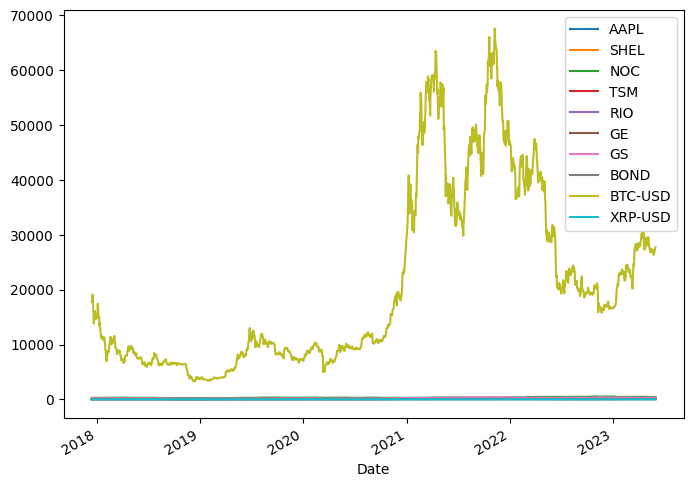

In [ ]:
data.plot(figsize=(8,6))

Daarna zetten we de dagkoersen om in dagrendementen:

In [ ]:
log_returns_na = np.log(data / data.shift(1))
log_returns = log_returns_na.dropna()
log_returns.head()

,AAPL,SHEL,NOC,TSM,RIO,GE,GS,BOND,BTC-USD,XRP-USD
Date,,,,,,,,,,
2017-12-18,0.013985,0.002316,-0.006690,-0.002535,0.015354,-0.003373,0.011021,-0.000094,0.076477,0.028969
2017-12-19,-0.010714,0.000771,-0.004159,-0.001524,-0.007849,-0.009618,-0.013708,-0.003482,-0.072543,0.016373
2017-12-20,-0.001089,0.003077,-0.001629,0.002539,0.021588,-0.007991,-0.005082,-0.001793,-0.067005,-0.019517
2017-12-21,0.003779,0.016454,-0.006971,-0.005339,0.016474,0.001145,0.022590,0.000000,-0.050690,0.430171
2017-12-22,0.000000,-0.006519,-0.002334,0.010144,-0.006244,0.001716,-0.007847,0.000095,-0.133223,-0.047003


array([[<Axes: title={'center': 'AAPL'}>,
        <Axes: title={'center': 'SHEL'}>,
        <Axes: title={'center': 'NOC'}>],
       [<Axes: title={'center': 'TSM'}>, <Axes: title={'center': 'RIO'}>,
        <Axes: title={'center': 'GE'}>],
       [<Axes: title={'center': 'GS'}>, <Axes: title={'center': 'BOND'}>,
        <Axes: title={'center': 'BTC-USD'}>],
       [<Axes: title={'center': 'XRP-USD'}>, <Axes: >, <Axes: >]],
      dtype=object)

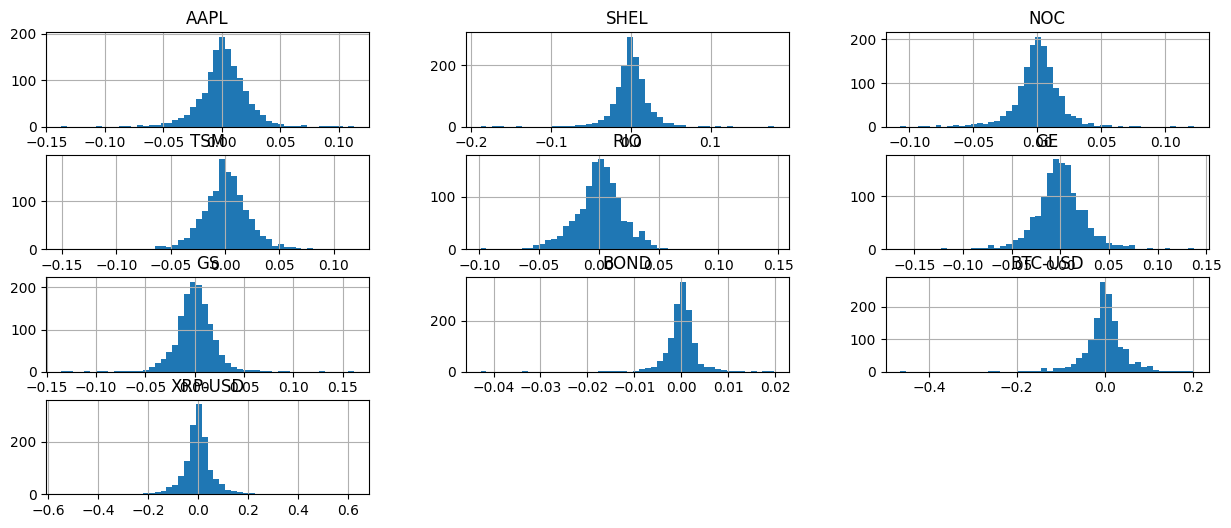

In [ ]:
log_returns.hist(bins=50, figsize=(15,6))

# Statistische analyse
Als eerste gaan we nu testen of de dagrendementen van onze aandelen, crypto's en obligaties in onze portfolio wel ' normaal'  verdeeld zijn. Daarvoor gebruiken we 2 functies: 

In [ ]:
def print_statistics(array):
  sta = scs.describe(array)
  print("%14s %15s" % ("statistic", "value"))
  print(30* "-")
  print("%14s %15.5f" % ("size",sta[0]))
  print("%14s %15.5f" % ("min",sta[1][0]))
  print("%14s %15.5f" % ("max",sta[1][1]))
  print("%14s %15.5f" % ("mean",sta[2]))
  print("%14s %15.5f" % ("std",np.sqrt(sta[3])))
  print("%14s %15.5f" % ("skew",sta[4]))
  print("%14s %15.5f" % ("kurtosis",sta[5]))

def normality_tests(arr):
  print("Skew of data set %14.3f" % scs.skew(arr))
  print("Skew test p-value %14.3f" % scs.skewtest(arr)[1])
  print("Kurt of data set %14.3f" % scs.kurtosis(arr))
  print("Kurt test p-value %14.3f" % scs.kurtosistest(arr)[1])
  print("Norm test p-value %14.3f" % scs.normaltest(arr)[1])

Als we deze 2 functies toepassen op onze portfolio, levert dat het volgende resultaat op. We beginnen met de ' statistics':

In [ ]:
for sym in symbols:
  print("\nResults for symbol %s" % sym)
  print(30 * "-")
  log_data = np.array(log_returns[sym].dropna())
  print_statistics(log_data)


Results for symbol AAPL
------------------------------
     statistic           value
------------------------------
          size      1370.00000
           min        -0.13771
           max         0.11316
          mean         0.00106
           std         0.02062
          skew        -0.23293
      kurtosis         4.74164

Results for symbol SHEL
------------------------------
     statistic           value
------------------------------
          size      1370.00000
           min        -0.18841
           max         0.17965
          mean         0.00010
           std         0.02299
          skew        -0.90585
      kurtosis        14.42306

Results for symbol NOC
------------------------------
     statistic           value
------------------------------
          size      1370.00000
           min        -0.10699
           max         0.12223
          mean         0.00032
           std         0.01788
          skew        -0.22817
      kurtosis         6.15

Conclusie?<br>

Is **negative skewness** good?<br>
A negative skew is generally not good, because it highlights the risk of left tail events or what are sometimes referred to as “[black swan events](https://en.wikipedia.org/wiki/Black_swan_theory).” While a consistent and steady track record with a positive mean would be a great thing, if the track record has a negative skew then you should proceed with caution.

What does it mean if **kurtosis** is above 3?<br>
If the kurtosis is greater than 3, then the dataset has heavier tails than a normal distribution (more in the tails). If the kurtosis is less than 3, then the dataset has lighter tails than a normal distribution (less in the tails).

En nu de 'normaliteitstest':

In [ ]:
for sym in symbols:
  print("\nResults for symbol %s" % sym)
  print(32 * "-")
  log_data = np.array(log_returns[sym].dropna())
  normality_tests(log_data)


Results for symbol AAPL
--------------------------------
Skew of data set         -0.233
Skew test p-value          0.000
Kurt of data set          4.742
Kurt test p-value          0.000
Norm test p-value          0.000

Results for symbol SHEL
--------------------------------
Skew of data set         -0.906
Skew test p-value          0.000
Kurt of data set         14.423
Kurt test p-value          0.000
Norm test p-value          0.000

Results for symbol NOC
--------------------------------
Skew of data set         -0.228
Skew test p-value          0.001
Kurt of data set          6.158
Kurt test p-value          0.000
Norm test p-value          0.000

Results for symbol TSM
--------------------------------
Skew of data set          0.100
Skew test p-value          0.129
Kurt of data set          3.699
Kurt test p-value          0.000
Norm test p-value          0.000

Results for symbol RIO
--------------------------------
Skew of data set          0.094
Skew test p-value          0.

Conclusie?<br>
Alle p-waarden zijn kleiner dan 0,05, dus we verwerpen de nulhypothese dat de dagrendementen normaal verdeeld zijn.

We kunnen er ook nog mooie plaatjes van maken:

Text(0, 0.5, 'sample quantiles')

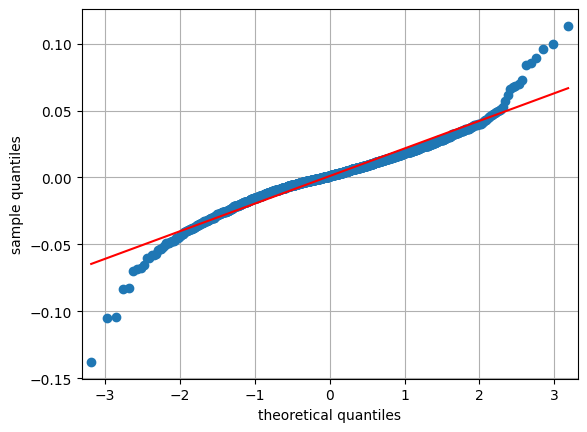

In [ ]:
sm.qqplot(log_returns['AAPL'].dropna(), line='s')
plt.grid(True)
plt.xlabel('theoretical quantiles')
plt.ylabel('sample quantiles')

En de plaatje(s) onderschrijven de eerdere conclusies:<br> de dagrendementen van de financiele waarden in onze portfolio zijn NIET normaal verdeeld: het staartrisico aan de linkerkant (= verlieszijde!) & aan de rechterkant (= winstzijde!) is te groot.

# Portfolio-optimalisatie
We gaan op basis van gewichten onze portfolio optimaliseren. We maken een nieuwe variabele aan ' rets' die gelijk is aan de log_returns van de statistische analyse. Verder maken we een variabele aan voor de [risicovrije rente](https://en.wikipedia.org/wiki/Risk-free_rate) (rf).

In [ ]:
rets = log_returns
rf = 0.02 # risicovrije rente van 2%

We maken een 'random' gewichtsverdeling voor onze portfolio:

In [ ]:
weights = np.random.random(noa)
weights /= np.sum(weights)
weights.round(2)

array([0.14, 0.17, 0.1 , 0.15, 0.  , 0.01, 0.04, 0.15, 0.07, 0.17])

Vervolgens berekenen we op basis van deze gewichten voor onze portfolio:<br>
- het verwachte rendement<br>
- de variantie<br>
- de standaardafwijking<br>
- de [Sharpe-ratio](https://en.wikipedia.org/wiki/Sharpe_ratio)

In [ ]:
epr = np.sum(rets.mean() * weights)*252 # expected portfolio return
print("The expected portfolio return is", epr.round(2))

epv = np.dot(weights.T, np.dot(rets.cov()*252, weights)) # expected portfolio variance
print("The expected portfolio variance is", epv.round(2))

eps = epv**0.5 # expected portfolio standard deviation
print("The expected portfolio standard deviation is", eps.round(2))

sharpe = (epr-rf)/eps # Sharpe ratio
print("The expected sharpe ratio is", sharpe.round(2))

The expected portfolio return is 0.08
The expected portfolio variance is 0.09
The expected portfolio standard deviation is 0.3
The expected sharpe ratio is 0.2


# Monte Carlo-simulatie
Met behulp van een Monte Carlo-simulatie maken we 2.500 portfolio's met verschillende gewichten.

In [ ]:
# Monte Carlo simulatie van alle mogelijke portfolio's:
prets = []
pvols = []

for p in range(2500):
  weights = np.random.random(noa)
  weights /= np.sum(weights)
  prets.append(np.sum(rets.mean() * weights)*252)
  pvols.append(np.sqrt(np.dot(weights.T, np.dot(rets.cov()*252, weights))))
  
prets = np.array(prets)
pvols = np.array(pvols)

In de grafiek zie je het resultaat van de simulatie, waarbij op de x-as de verwachte variantie = volatiliteit staat en op de y-as het verwachte rendement.

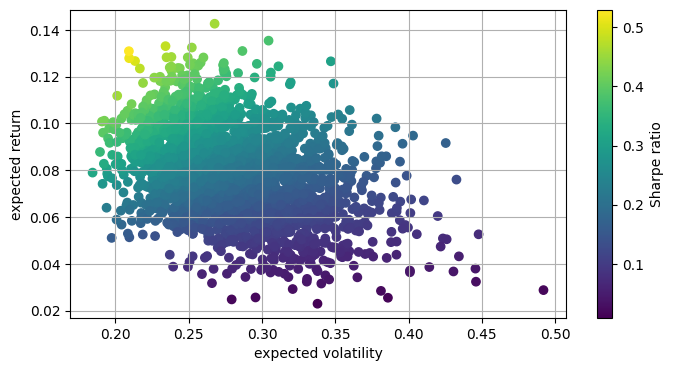

In [ ]:
plt.figure(figsize=(8,4))
plt.scatter(pvols,prets, c=(prets-rf)/pvols, marker='o')
plt.grid(True)
plt.xlabel('expected volatility')
plt.ylabel('expected return')
plt.colorbar(label='Sharpe ratio')

# Optimalisatie
Om te optimaliseren hebben we wat nieuwe functies nodig:

In [ ]:
from pyparsing.helpers import OpAssoc
import scipy.optimize as sco

We maken 3 functies aan:<br>
- een functie ('statistics') die het rendement, risco en de Sharpe-ratio van de portfolio's berekent<br>
- een functie ('min_variance') die de gewichten berekent voor een portfolio met minimaal risico<br>
- een functie ('min_sharpe') die de gewichten berekent voor een portfolio met een MAXIMALE Sharpe-ratio

In [ ]:
def statistics(weights):
  weights = np.array(weights)
  pret = np.sum(rets.mean() * weights)*252
  pvol = np.sqrt(np.dot(weights.T, np.dot(rets.cov()*252, weights)))
  return np.array([pret, pvol, (pret-rf)/pvol])

def min_func_variance(weights):
  return statistics(weights)[1]**2

def min_func_sharpe(weights):
  return -statistics(weights)[2]

Vervolgens laten we het algoritme ('[SLSQP](https://docs.scipy.org/doc/scipy/reference/optimize.minimize-slsqp.html)') de optimale gewichten berekenen:

In [ ]:
cons = ({'type':'eq', 'fun': lambda x: np.sum(x)-1 })
bnds = tuple((0,1) for x in range(noa))

opts = sco.minimize(min_func_sharpe, noa * [1./noa,], method='SLSQP', bounds=bnds, constraints=cons)
optv = sco.minimize(min_func_variance, noa * [1./noa,], method='SLSQP', bounds=bnds, constraints=cons)

Optimale gewichten voor maximale Sharpe-ratio:

In [ ]:
print(opts['x'].round(2)) # optimale gewichten voor maximale Sharpe-ratio
print(statistics(opts['x']).round(2)) # het rendement, de standaardafwijking en de Sharpe-ratio van de portefeuille met max Sharpe

[0.85 0.   0.   0.15 0.   0.   0.   0.   0.   0.  ]
[0.26 0.31 0.77]


Optimale gewichten voor minimale variantie = minimaal risico:

In [ ]:
print(optv['x'].round(2)) # optimale gewichten voor minimal variance
print(statistics(optv['x']).round(2)) # het rendement, de standaardafwijking en de Sharpe-ratio van de portefeuille met min variance

[0.   0.   0.02 0.   0.   0.   0.   0.97 0.   0.  ]
[ 0.01  0.05 -0.27]


# De Grenslijn met de optimale portfolio's
We gaan de grafiek nog wat mooier maken door er de [efficiente grenslijn](https://en.wikipedia.org/wiki/Efficient_frontier) aan toe te voegen, bedacht door [Harry Markowitz](https://en.wikipedia.org/wiki/Harry_Markowitz).

We starten bij de portfolio met het minste risico, en van daar af bouwen we de lijn op:

In [ ]:
def min_func_port(weights):
  return statistics(weights)[1]

cons = ({'type':'eq', 'fun': lambda x: statistics(x)[0]-tret },{'type':'eq', 'fun': lambda x: np.sum(x)-1})
bnds = tuple((0,1) for x in weights)

trets = np.linspace(0.0,0.25,50)
tvols = []

for tret in trets:
  cons = ({'type':'eq', 'fun': lambda x: statistics(x)[0]-tret },{'type':'eq', 'fun': lambda x: np.sum(x)-1})
  res = sco.minimize(min_func_port, noa * [1./noa,], method='SLSQP', bounds=bnds, constraints=cons)
  tvols.append(res['fun'])

Alles is berekend, tijd voor de grafiek:

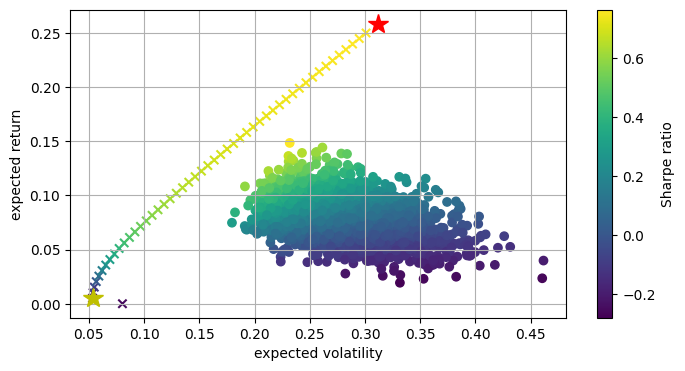

In [ ]:
plt.figure(figsize=(8,4))
plt.scatter(pvols,prets, c=(prets-rf)/pvols, marker='o') # random portfolio's
plt.scatter(tvols,trets, c=(trets-rf)/tvols, marker='x') # efficient portfolio's
plt.plot(statistics(opts['x'])[1],statistics(opts['x'])[0], 'r*',markersize=15.0 ) # portfolio met max Sharpe
plt.plot(statistics(optv['x'])[1],statistics(optv['x'])[0], 'y*',markersize=15.0 ) # portfolio met min variance
plt.grid(True)
plt.xlabel('expected volatility')
plt.ylabel('expected return')
plt.colorbar(label='Sharpe ratio')



# De Security Market-lijn met de marktportfolio
Tot slot vervolmaken we de grafiek door er de [Security Market Line](https://en.wikipedia.org/wiki/Security_market_line) aan toe te voegen: alle portfolio's op deze lijn zijn optimaal (en samen te stellen door te lenen of te sparen), het hangt van je eigen risicovoorkeur af welke je kiest. 

We lezen eerst wat extra functies in:

In [ ]:
import scipy.interpolate as sci
from pyparsing.helpers import OpAssoc
import scipy.optimize as sco

Vervolgens gebruiken we drie functies om de lijn te berekenen:

In [ ]:
ind = np.argmin(tvols)
evols = tvols[ind:]
erets = trets[ind:]

tck = sci.splrep(evols, erets)

def f(x):
  return sci.splev(x, tck, der=0)

def df(x):
  return sci.splev(x, tck, der=1)

def equations(p, rf=0.01):
  eq1 = rf - p[0]
  eq2 = rf + p[1] * p[2] -f(p[2])
  eq3 = p[1] - df(p[2])
  return eq1, eq2, eq3

opt = sco.fsolve(equations, [0.01,0.2,0.2])

np.round(equations(opt),6)

cons = ({'type':'eq', 'fun': lambda x: statistics(x)[0]-f(opt[2]) },{'type':'eq', 'fun': lambda x: np.sum(x)-1})
res = sco.minimize(min_func_port, noa * [1./noa,], method='SLSQP', bounds=bnds, constraints=cons)

/usr/local/lib/python3.10/dist-packages/scipy/optimize/_minpack_py.py:178: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  warnings.warn(msg, RuntimeWarning)


Alles berekend, tijd voor de laatste grafiek:

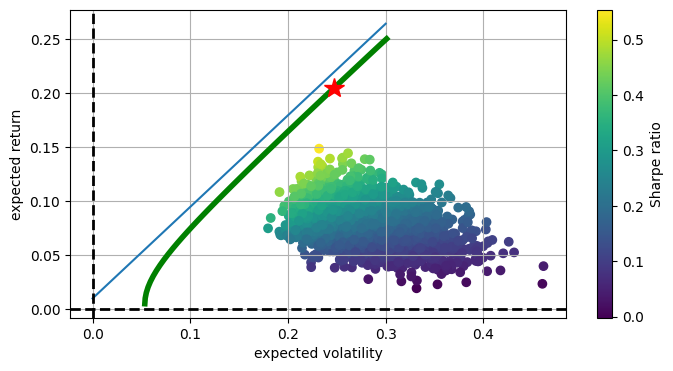

In [ ]:
plt.figure(figsize=(8,4))
plt.scatter(pvols,prets, c=(prets-rf)/pvols, marker='o') # random portfolio's
plt.plot(evols, erets,'g', lw=4.0 ) # efficient frontier
cx = np.linspace(0.0, 0.3)
plt.plot(cx, opt[0] + opt[1] * cx, lw=1.5) # capital market line
plt.plot(opt[2], f(opt[2]), 'r*', markersize=15.0)  # marktportfolio
plt.grid(True)
plt.axhline(0, color='k', ls='--', lw=2.0)
plt.axvline(0, color='k', ls='--', lw=2.0)
plt.xlabel('expected volatility')
plt.ylabel('expected return')
plt.colorbar(label='Sharpe ratio')

De rode ster geeft de portfolio aan met de maximale Sharpe-ratio. Deze portfolio noemen we ook wel de marktportfolio. Om deze portfolio samen te stellen met behulp van onze portfolio, zou je de volgende gewichten moeten gebruiken:

In [ ]:
print(res['x'].round(2)) # gewichten van de marktportfolio

[0.63 0.   0.05 0.13 0.02 0.   0.   0.16 0.   0.  ]


De marktportfolio heeft onderstaand(e) rendement, standaardafwijking en Sharpe-ratio:

In [ ]:
print(statistics(res['x']).round(2)) # rendement, standaardafwijking en sharpe-ratio van de marktportfolio

[0.2  0.25 0.75]


NB: de 'echte' (wereld)marktportfolio zou een samenstelling van alle beschikbare financiele producten ter wereld moeten zijn, dat is practisch niet helemaal haalbaar ..<br>

Je bent dus nooit helemaal ' optimaal' gespreid, er blijft altijd een landen / sector / valuta / etc risico over.